# beta-VAE: Learning Basic Visual Concepts with a Constrained Variational Framework — Figure 7A–B

In [1]:
import hashlib
import json
import math
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as functional
import torchvision
from IPython.display import display


project_hint = Path(os.environ.get("ASSIGNMENT2_DIR", Path.cwd())).expanduser().resolve()
project_candidates = [
    candidate
    for ancestor in (project_hint, *project_hint.parents)
    for candidate in (ancestor, ancestor / "paper_3_beta_vae",
                      ancestor / "Assignemnt_2" / "paper_3_beta_vae")
]
PROJECT_DIR = next((candidate for candidate in project_candidates
                    if (candidate / "beta_vae_learning_basic_visual_concepts.ipynb").is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Open this notebook from its paper folder or set ASSIGNMENT2_DIR to the assignment root.")
DATA_DIR = next((ancestor / "data" for ancestor in (PROJECT_DIR, *PROJECT_DIR.parents)
                 if (ancestor / "data").is_dir()), PROJECT_DIR / "data")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def atomic_json(destination, value):
    destination = Path(destination)
    temporary = destination.with_suffix(destination.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False))
    temporary.replace(destination)


def atomic_torch(destination, value):
    destination = Path(destination)
    temporary = destination.with_suffix(destination.suffix + ".tmp")
    torch.save(value, temporary)
    temporary.replace(destination)


def random_state():
    numpy_state = np.random.get_state()
    return {"python": random.getstate(), "numpy": [numpy_state[0], numpy_state[1].tolist(),
            int(numpy_state[2]), int(numpy_state[3]), float(numpy_state[4])],
            "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}


def restore_random_state(state):
    random.setstate(state["python"])
    numpy_state = state["numpy"]
    np.random.set_state((numpy_state[0], np.asarray(numpy_state[1], dtype=np.uint32), *numpy_state[2:]))
    torch.set_rng_state(state["torch"].cpu())
    if state["cuda"] is not None:
        if not torch.cuda.is_available() or len(state["cuda"]) != torch.cuda.device_count():
            raise RuntimeError("Checkpoint CUDA device configuration differs.")
        torch.cuda.set_rng_state_all([value.cpu() for value in state["cuda"]])


def model_digest(model):
    digest = hashlib.sha256()
    for name, value in model.state_dict().items():
        digest.update(name.encode())
        digest.update(value.detach().cpu().numpy().tobytes())
    return digest.hexdigest()


def environment_metadata():
    return {"torch": str(torch.__version__), "torchvision": str(torchvision.__version__),
            "numpy": str(np.__version__), "device": str(DEVICE), "precision": "float32_no_tf32"}


def verify_resume_environment(saved):
    if saved != environment_metadata():
        raise RuntimeError("Resume environment changed; retain the checkpoint and use a separate run.")


def completed_experiment(directory, config):
    config_path = directory / "config.json"
    summary_path = directory / "summary.json"
    saved_config = json.loads(config_path.read_text()) if config_path.exists() else None
    if saved_config is not None:
        expected = {key: value for key, value in config.items() if key != "environment"}
        existing = {key: value for key, value in saved_config.items() if key != "environment"}
        if existing != expected:
            raise ValueError("Existing experiment settings differ; use a new results directory.")
    if summary_path.exists():
        summary = json.loads(summary_path.read_text())
        if saved_config is None or summary["config"] != saved_config or summary["status"] != "completed":
            raise ValueError("Completed result metadata is inconsistent.")
        return {**summary, "directory": str(directory)}
    if saved_config is None:
        atomic_json(config_path, config)
    else:
        verify_resume_environment(saved_config["environment"])
    return None


In [2]:
SEED = 42
BETAS = (4.0, 1.0)
BATCH_SIZE = 256
EPOCHS = 100
LEARNING_RATE = 0.01
LATENT_SIZE = 10
ANALYSIS_BATCH = 2048
TRAVERSAL_VALUES = np.linspace(3, -3, 5, dtype=np.float32)
RESULTS_DIR = PROJECT_DIR / "results_beta_vae" / "seed42_v1"
IMPLEMENTATION = "higgins-figure7-v1"
DSPRITES = None


def load_dsprites():
    global DSPRITES
    if DSPRITES is None:
        directory = DATA_DIR / "dsprites"
        if (directory / "images.npy").exists():
            images = np.load(directory / "images.npy", mmap_mode="r", allow_pickle=False)
            classes = np.load(directory / "latents_classes.npy", allow_pickle=False)
            values = np.load(directory / "latents_values.npy", allow_pickle=False)
        else:
            archive = directory / "dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz"
            with np.load(archive, allow_pickle=False) as contents:
                images = contents["imgs"]
                classes = contents["latents_classes"]
                values = contents["latents_values"]
        source = json.loads((directory / "source.json").read_text())
        if images.shape != (737280, 64, 64) or classes.shape != (737280, 6):
            raise ValueError("Expected the complete 737,280-image dSprites dataset.")
        probes = np.random.default_rng(99).integers(0, len(images), 100)
        expected = np.stack(np.unravel_index(probes, (3, 6, 40, 32, 32)), axis=1)
        if not np.array_equal(classes[probes, 1:], expected):
            raise ValueError("Factor ordering differs from the analysis grid.")
        cached_images = torch.from_numpy(np.array(images, dtype=np.uint8, copy=True)).to(DEVICE)
        DSPRITES = {"images": cached_images, "classes": classes, "values": values, "source": source}
    return DSPRITES


class ShapesVAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(4096, 1200), nn.ReLU(),
                                     nn.Linear(1200, 1200), nn.ReLU())
        self.mean = nn.Linear(1200, LATENT_SIZE)
        self.log_variance = nn.Linear(1200, LATENT_SIZE)
        self.decoder = nn.Sequential(nn.Linear(LATENT_SIZE, 1200), nn.Tanh(),
                                     nn.Linear(1200, 1200), nn.Tanh(),
                                     nn.Linear(1200, 1200), nn.Tanh(), nn.Linear(1200, 4096))
        self.apply(self.initialize)

    @staticmethod
    def initialize(module):
        if isinstance(module, nn.Linear):
            nn.init.xavier_uniform_(module.weight)
            nn.init.zeros_(module.bias)

    def encode(self, images):
        features = self.encoder(images)
        return self.mean(features), self.log_variance(features)

    def decode(self, latents):
        return self.decoder(latents)

    def forward(self, images):
        mean, log_variance = self.encode(images)
        latents = mean + torch.exp(0.5 * log_variance) * torch.randn_like(mean)
        return self.decode(latents), mean, log_variance


def vae_terms(logits, images, mean, log_variance):
    reconstruction = functional.binary_cross_entropy_with_logits(
        logits, images.flatten(1), reduction="none").sum(1)
    divergence = 0.5 * (mean.square() + log_variance.exp() - 1 - log_variance).sum(1)
    return reconstruction, divergence


In [3]:
def vae_configuration(beta, data):
    return {"implementation": IMPLEMENTATION, "beta": float(beta), "seed": SEED,
            "epochs": EPOCHS, "batch_size": BATCH_SIZE, "latent_size": LATENT_SIZE,
            "optimizer": "Adagrad", "lr": LEARNING_RATE, "lr_decay": 0,
            "initial_accumulator_value": 0.1, "eps": 1e-10, "weight_decay": 0,
            "encoder": [4096, 1200, 1200], "decoder": [10, 1200, 1200, 1200, 4096],
            "encoder_activation": "relu", "decoder_hidden_activation": "tanh",
            "observation": "bernoulli_logits", "initialization": "xavier_uniform_bias_zero",
            "loss": "mean_examples(sum_pixels_BCE_plus_beta_sum_latents_KL)",
            "training_count": len(data["images"]), "dataset": data["source"],
            "environment": environment_metadata()}


def train_vae(beta, data=None, pause_after_epoch=None):
    data = load_dsprites() if data is None else data
    images = data["images"]
    config = vae_configuration(beta, data)
    directory = RESULTS_DIR / f"beta{beta:g}_seed{SEED}"
    directory.mkdir(parents=True, exist_ok=True)
    completed = completed_experiment(directory, config)
    if completed is not None:
        return completed
    seed_everything(SEED)
    model = ShapesVAE().to(DEVICE)
    initial_digest = model_digest(model)
    optimizer = torch.optim.Adagrad(model.parameters(), lr=LEARNING_RATE, lr_decay=0,
                                   weight_decay=0, initial_accumulator_value=0.1, eps=1e-10)
    checkpoint_path = directory / "checkpoint.pt"
    history = []
    start_epoch, steps = 0, 0
    if checkpoint_path.exists():
        saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
        verify_resume_environment(saved["config"]["environment"])
        if saved["config"] != config:
            raise ValueError("Checkpoint configuration differs.")
        model.load_state_dict(saved["model"])
        optimizer.load_state_dict(saved["optimizer"])
        history, start_epoch, steps = saved["history"], saved["epoch"], saved["steps"]
        restore_random_state(saved["rng"])
    for epoch in range(start_epoch, EPOCHS):
        started = time.perf_counter()
        generator = torch.Generator().manual_seed(SEED + epoch)
        order = torch.randperm(len(images), generator=generator).to(DEVICE)
        model.train()
        totals = torch.zeros(2, dtype=torch.float64, device=DEVICE)
        for start in range(0, len(order), BATCH_SIZE):
            batch = images[order[start:start + BATCH_SIZE]].float()
            optimizer.zero_grad(set_to_none=True)
            logits, mean, log_variance = model(batch)
            reconstruction, divergence = vae_terms(logits, batch, mean, log_variance)
            loss = (reconstruction + beta * divergence).mean()
            loss.backward()
            optimizer.step()
            totals[0] += reconstruction.detach().sum()
            totals[1] += divergence.detach().sum()
            steps += 1
        reconstruction_sum, divergence_sum = totals.cpu().tolist()
        if not math.isfinite(reconstruction_sum + divergence_sum):
            raise RuntimeError(f"Nonfinite VAE objective; previous epoch checkpoint retained: {directory}")
        record = {"epoch": epoch + 1, "steps": steps,
                  "reconstruction": reconstruction_sum / len(images),
                  "kl": divergence_sum / len(images),
                  "objective": (reconstruction_sum + beta * divergence_sum) / len(images),
                  "seconds": time.perf_counter() - started}
        history.append(record)
        saved = {"config": config, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
                 "epoch": epoch + 1, "steps": steps, "history": history, "rng": random_state(),
                 "initial_digest": initial_digest}
        atomic_torch(checkpoint_path, saved)
        atomic_json(directory / "history.json", history)
        print(f"beta={beta:g}: epoch {epoch + 1}/{EPOCHS}, reconstruction {record['reconstruction']:.3f}, KL {record['kl']:.3f}, {record['seconds']:.2f}s", flush=True)
        if pause_after_epoch is not None and epoch + 1 >= pause_after_epoch and epoch + 1 < EPOCHS:
            return {"status": "paused", "directory": str(directory), "epoch": epoch + 1}
    summary = {"status": "completed", "config": config, "beta": float(beta), "epochs": len(history),
               "steps": steps, "last_epoch": history[-1], "initial_digest": initial_digest,
               "parameters": sum(parameter.numel() for parameter in model.parameters()),
               "directory": str(directory)}
    atomic_json(directory / "summary.json", summary)
    del model, optimizer
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return summary


@torch.no_grad()
def analyze_vae(summary, data=None):
    data = load_dsprites() if data is None else data
    directory = Path(summary["directory"])
    checkpoint_path = directory / "checkpoint.pt"
    signature = {"checkpoint_sha256": hashlib.sha256(checkpoint_path.read_bytes()).hexdigest(),
                 "reference_factors": [1, 3, 0, 16, 16], "traversal": TRAVERSAL_VALUES.tolist(),
                 "ordering": "ascending_mean_posterior_variance", "analysis_images": len(data["images"])}
    analysis_path = directory / "analysis.npz"
    if analysis_path.exists() and (directory / "analysis_signature.json").exists():
        if json.loads((directory / "analysis_signature.json").read_text()) != signature:
            raise ValueError("Analysis settings or checkpoint differ.")
        with np.load(analysis_path, allow_pickle=False) as saved:
            return {key: saved[key] for key in saved.files}
    saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    model = ShapesVAE().to(DEVICE).eval()
    model.load_state_dict(saved["model"])
    means = np.empty((len(data["images"]), LATENT_SIZE), dtype=np.float32)
    log_variances = np.empty_like(means)
    reconstruction_sum = torch.zeros((), dtype=torch.float64, device=DEVICE)
    for start in range(0, len(means), ANALYSIS_BATCH):
        batch = data["images"][start:start + ANALYSIS_BATCH].float()
        mean, log_variance = model.encode(batch)
        logits = model.decode(mean)
        reconstruction_sum += functional.binary_cross_entropy_with_logits(logits, batch.flatten(1), reduction="sum")
        means[start:start + len(batch)] = mean.cpu().numpy()
        log_variances[start:start + len(batch)] = log_variance.cpu().numpy()
    if not np.isfinite(means).all() or not np.isfinite(log_variances).all():
        raise RuntimeError("Nonfinite inferred latent statistics.")
    variance = np.exp(log_variances)
    if not np.isfinite(variance).all():
        raise RuntimeError("Nonfinite posterior variances.")
    mean_variance = variance.mean(axis=0, dtype=np.float64)
    mean_kl = (0.5 * (means**2 + variance - 1 - log_variances)).mean(axis=0, dtype=np.float64)
    response_grid = means.reshape(3, 6, 40, 32, 32, LATENT_SIZE)
    reference_index = int(np.ravel_multi_index(tuple(signature["reference_factors"]), (3, 6, 40, 32, 32)))
    reference_mean = torch.from_numpy(means[reference_index]).to(DEVICE)
    traversals = []
    for latent_index in range(LATENT_SIZE):
        latents = reference_mean.repeat(len(TRAVERSAL_VALUES), 1)
        latents[:, latent_index] = torch.as_tensor(TRAVERSAL_VALUES, device=DEVICE)
        traversals.append(torch.sigmoid(model.decode(latents)).reshape(-1, 64, 64).cpu().numpy())
    result = {"position": response_grid.mean(axis=(0, 1, 2), dtype=np.float64),
              "scale": response_grid.mean(axis=(2, 3, 4), dtype=np.float64),
              "rotation": response_grid.mean(axis=(1, 3, 4), dtype=np.float64),
              "mean_variance": mean_variance, "mean_kl": mean_kl,
              "order": np.argsort(mean_variance, kind="stable"), "traversals": np.stack(traversals),
              "reference_image": data["images"][reference_index].cpu().numpy(),
              "reference_mean": reference_mean.cpu().numpy(),
              "scale_values": np.unique(data["values"][:, 2]),
              "rotation_values": np.unique(data["values"][:, 3]),
              "posterior_mean_reconstruction": np.asarray(reconstruction_sum.item() / len(means))}
    temporary = directory / "analysis.tmp"
    with temporary.open("wb") as handle:
        np.savez_compressed(handle, **result)
    temporary.replace(analysis_path)
    atomic_json(directory / "analysis_signature.json", signature)
    return result


In [4]:
vae_summaries = [train_vae(beta) for beta in BETAS]
if len({summary["initial_digest"] for summary in vae_summaries}) != 1:
    raise ValueError("The two VAE conditions did not share initial weights.")
vae_analyses = {summary["beta"]: analyze_vae(summary) for summary in vae_summaries}


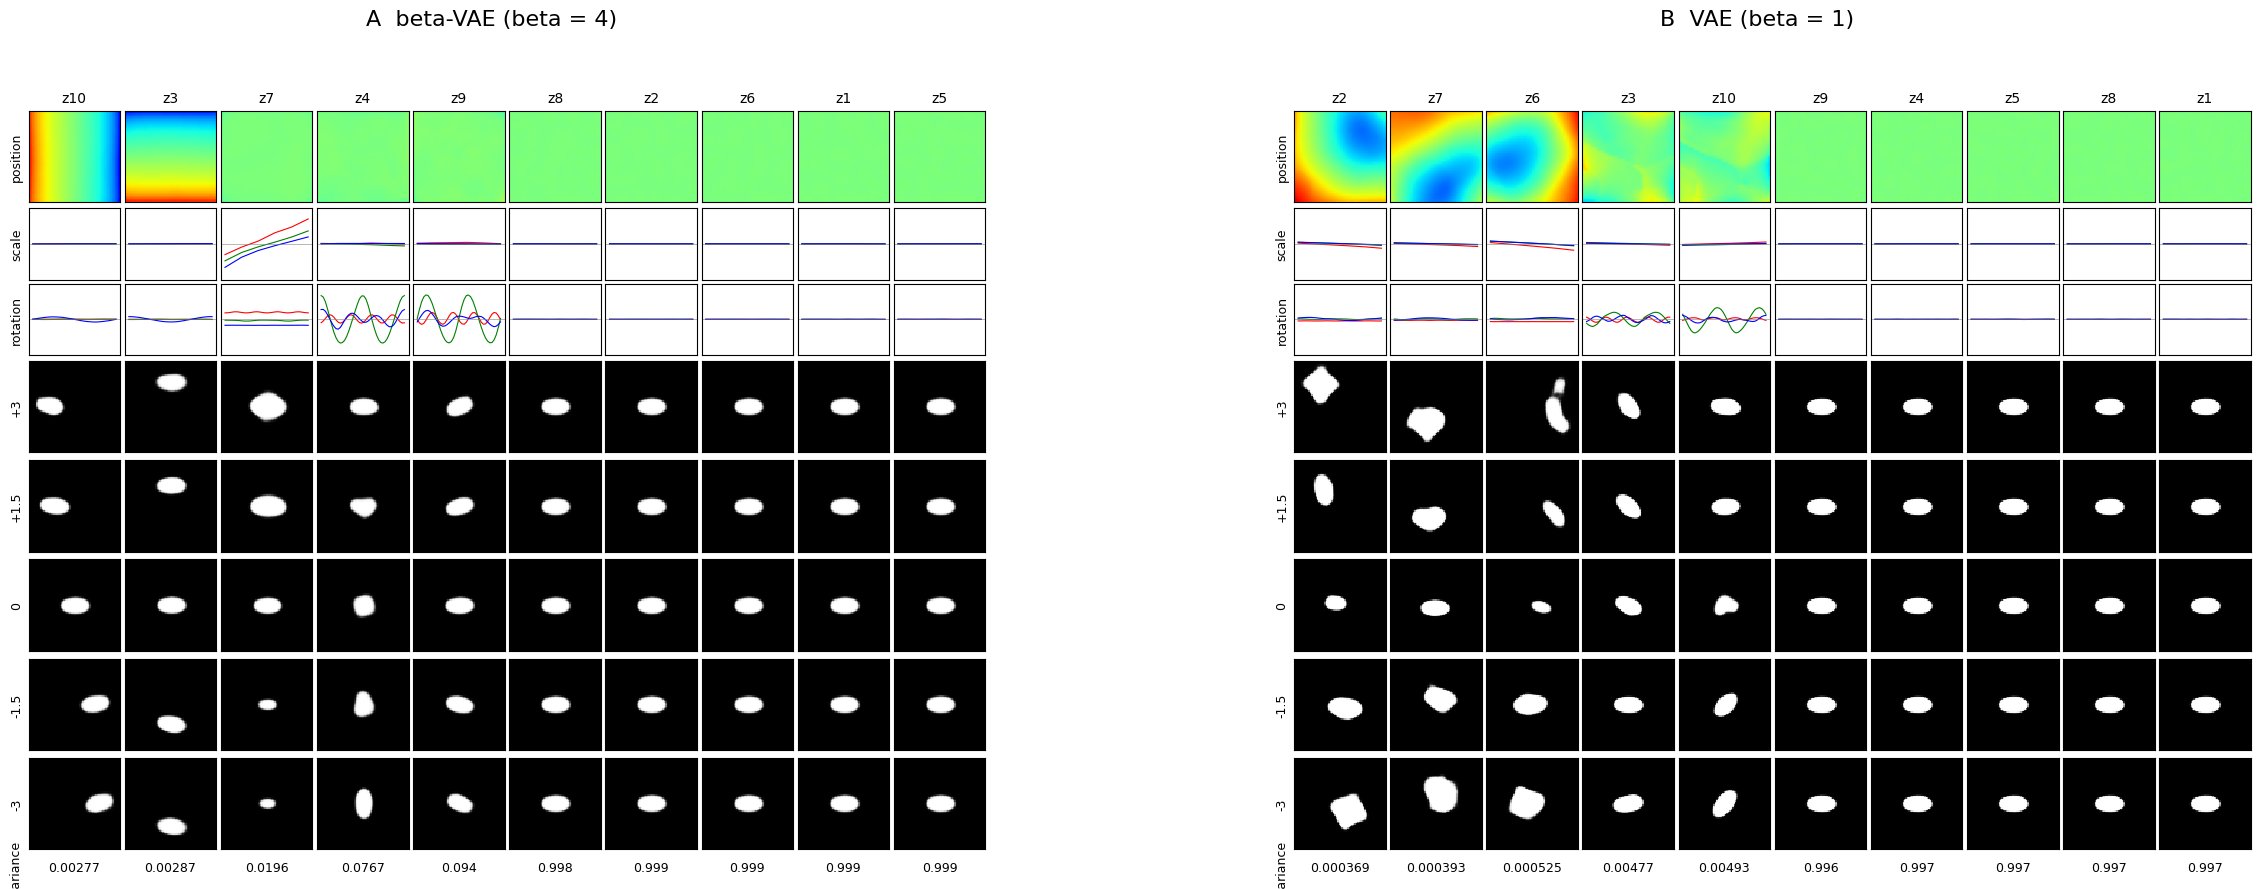

[
  {
    "beta": 4.0,
    "epochs": 100,
    "posterior_mean_reconstruction_nats": 45.14476760758294,
    "mean_kl_nats": 11.90019160946108,
    "ordered_latent_ids": [
      10,
      3,
      7,
      4,
      9,
      8,
      2,
      6,
      1,
      5
    ],
    "ordered_posterior_variances": [
      0.002772690661424113,
      0.0028744094537033267,
      0.019628334061755164,
      0.07669909374278253,
      0.09401782241847438,
      0.9982031904722842,
      0.9986958699471467,
      0.9988320445791437,
      0.9989784440192225,
      0.9992292649442486
    ]
  },
  {
    "beta": 1.0,
    "epochs": 100,
    "posterior_mean_reconstruction_nats": 33.45641389158037,
    "mean_kl_nats": 17.606148353288003,
    "ordered_latent_ids": [
      2,
      7,
      6,
      3,
      10,
      9,
      4,
      5,
      8,
      1
    ],
    "ordered_posterior_variances": [
      0.0003689839146824624,
      0.00039303390929034245,
      0.0005249026248537231,
      0.004765544264707620

In [5]:
figure = plt.figure(figsize=(25, 10))
panels = figure.subfigures(1, 2, wspace=0.025)
response_limit = max(3.0, max(float(np.abs(analysis[name]).max())
                            for analysis in vae_analyses.values() for name in ("position", "scale", "rotation")))
for panel, beta, label in zip(panels, BETAS, ("A", "B")):
    analysis = vae_analyses[beta]
    axes = panel.subplots(9, LATENT_SIZE, gridspec_kw={"height_ratios": [1, 0.75, 0.75, 1, 1, 1, 1, 1, 0.25],
                                                     "hspace": 0.05, "wspace": 0.05})
    panel.suptitle(f"{label}  {'beta-VAE' if beta == 4 else 'VAE'} (beta = {beta:g})", fontsize=16)
    for column, latent_index in enumerate(analysis["order"]):
        axes[0, column].imshow(analysis["position"][:, :, latent_index].T, origin="lower", cmap="jet",
                              vmin=-response_limit, vmax=response_limit)
        axes[0, column].set_title(f"z{latent_index + 1}", fontsize=10)
        for row, response, factor_values in ((1, "scale", "scale_values"), (2, "rotation", "rotation_values")):
            for shape_index, color in enumerate(("red", "green", "blue")):
                axes[row, column].plot(analysis[factor_values], analysis[response][shape_index, :, latent_index],
                                       color=color, linewidth=0.8)
            axes[row, column].set_ylim(-response_limit, response_limit)
            axes[row, column].axhline(0, color="gray", linewidth=0.4)
        for traversal_index in range(len(TRAVERSAL_VALUES)):
            axes[3 + traversal_index, column].imshow(analysis["traversals"][latent_index, traversal_index],
                                                    cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        axes[8, column].text(0.5, 0.5, f"{analysis['mean_variance'][latent_index]:.3g}",
                             ha="center", va="center", fontsize=9)
        for row in range(9):
            axes[row, column].set_xticks([])
            axes[row, column].set_yticks([])
            if row == 8:
                axes[row, column].set_frame_on(False)
    for row, text_label in enumerate(("position", "scale", "rotation", "+3", "+1.5", "0", "-1.5", "-3", "variance")):
        axes[row, 0].set_ylabel(text_label, fontsize=9)
figure.savefig(RESULTS_DIR / "figure7ab.png", dpi=180, bbox_inches="tight")
figure.savefig(RESULTS_DIR / "figure7ab.pdf", bbox_inches="tight")
plt.show()
vae_metrics = [{"beta": beta, "epochs": next(summary["epochs"] for summary in vae_summaries if summary["beta"] == beta),
                "posterior_mean_reconstruction_nats": float(vae_analyses[beta]["posterior_mean_reconstruction"]),
                "mean_kl_nats": float(vae_analyses[beta]["mean_kl"].sum()),
                "ordered_latent_ids": (vae_analyses[beta]["order"] + 1).tolist(),
                "ordered_posterior_variances": vae_analyses[beta]["mean_variance"][vae_analyses[beta]["order"]].tolist()}
               for beta in BETAS]
atomic_json(RESULTS_DIR / "metrics.json", vae_metrics)
print(json.dumps(vae_metrics, indent=2))


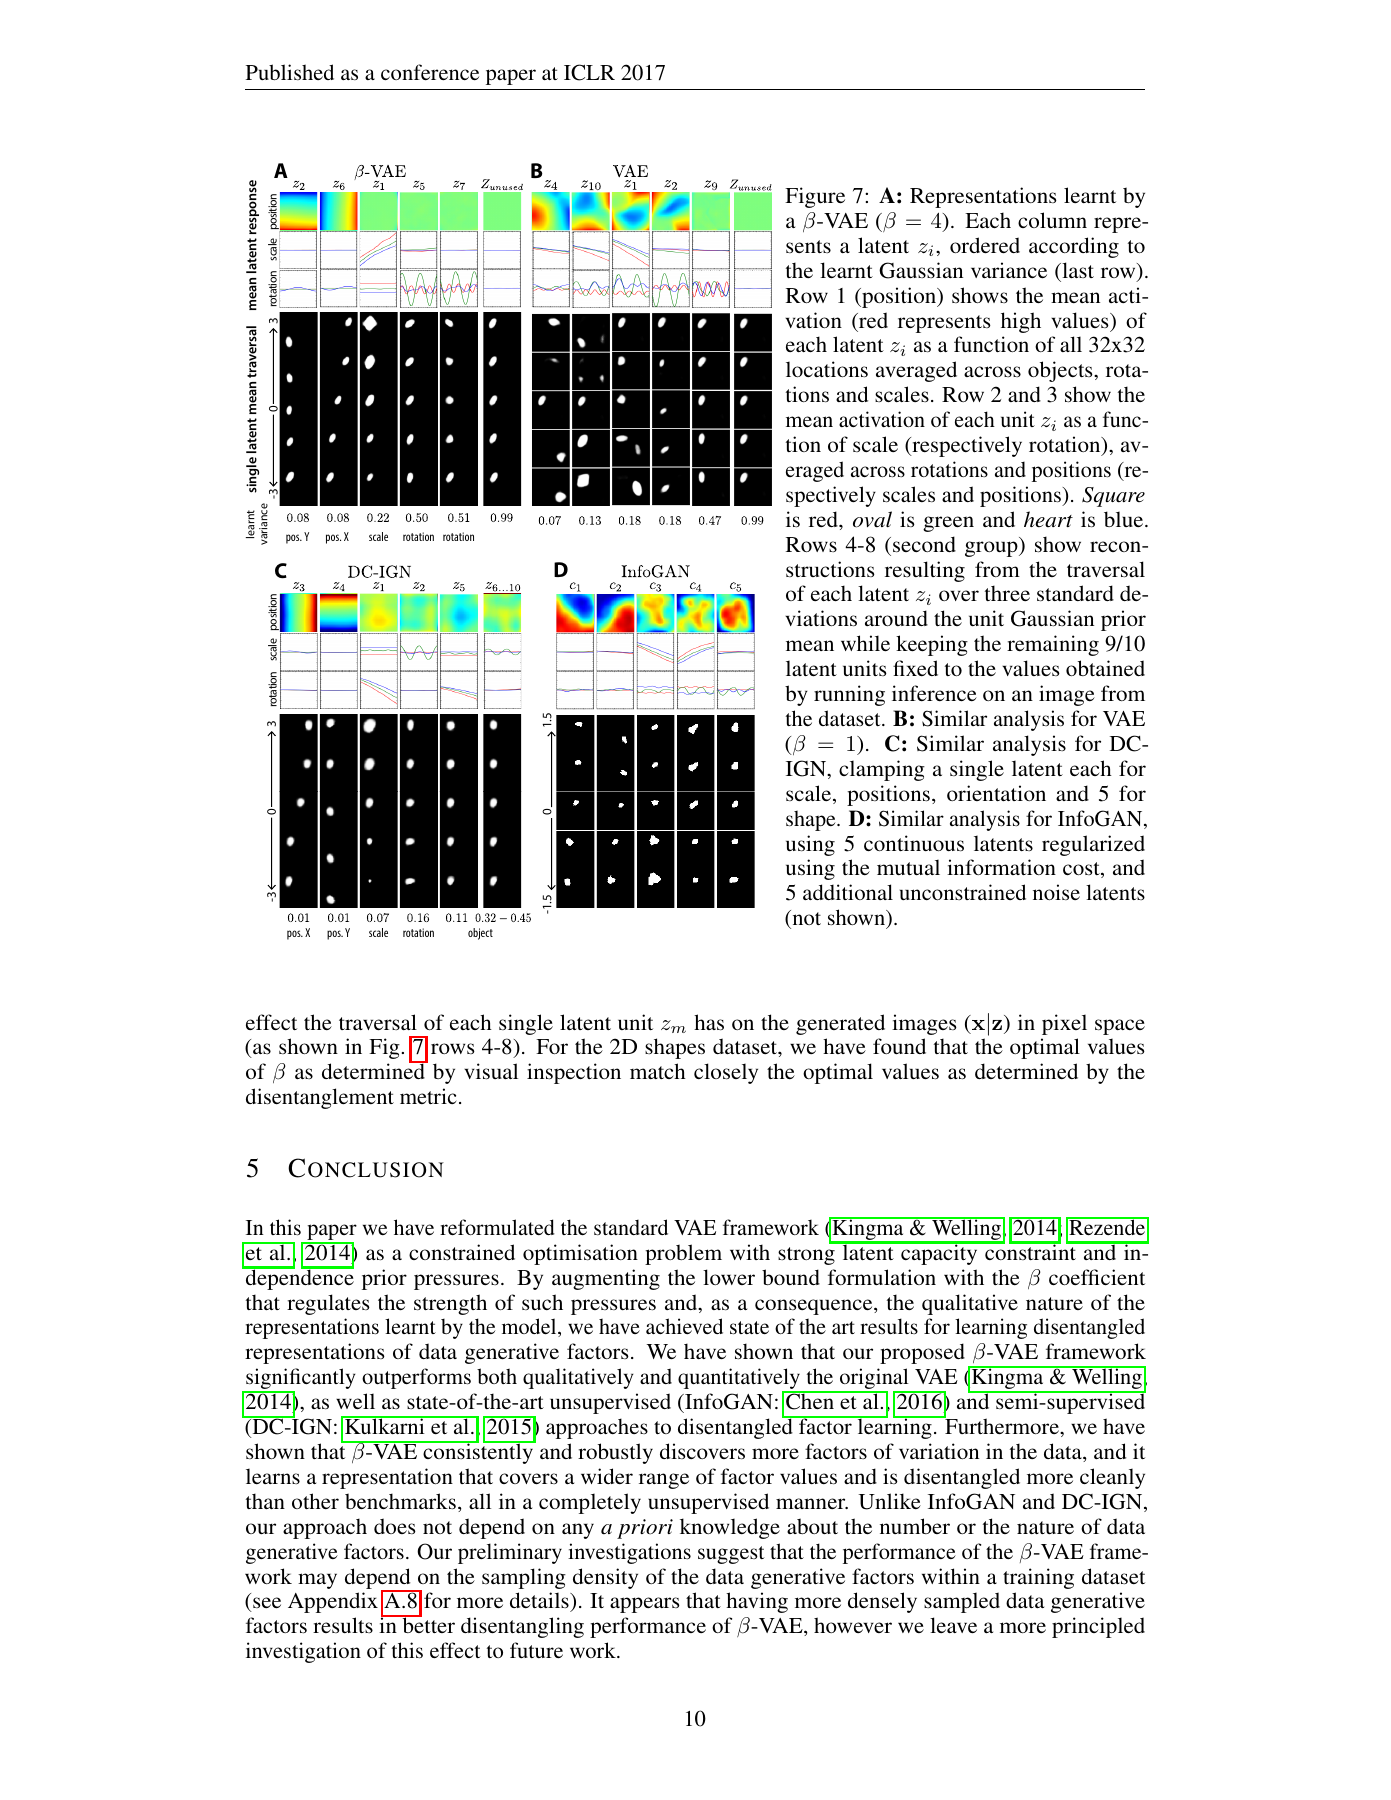

In [6]:
from IPython.display import Image

display(Image(filename=str(PROJECT_DIR / "results_beta_vae/figure7_reference.png")))
